In [ ]:
#Dossier du projet
%cd "/Users/bilal/Desktop/Master 1/ADD/FTD2"

C:\Users\bilal\Desktop\Master 1\ADD\FTD2


In [2]:
#Bib pandas pour manipulation des données
import pandas as pd

In [ ]:
#appel du fichier csv du projet et le mettre dans un DF de pandas
df = pd.read_csv("exo1.csv")

In [ ]:
#afficher des informations sur le dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Marque  9 non-null      str  
 1   X       9 non-null      int64
 2   Y       9 non-null      int64
 3   Z       9 non-null      int64
 4   Groupe  9 non-null      str  
dtypes: int64(3), str(2)
memory usage: 585.0 bytes


In [ ]:
#separation des individus de base (A,B,C...,F) et (G,H,I) par la nouvelle colonne ajoutée "Groupe"
bases = df[df['Groupe']=="initial"].set_index('Marque')[["X","Y","Z"]]
supp = df[df['Groupe']=="supplementaire"].set_index('Marque')[["X","Y","Z"]]

In [6]:
#pyplot et seaborn pour la visualisation et le graphe de nuages de points (scatter)
import matplotlib.pyplot as plt
import seaborn as sns

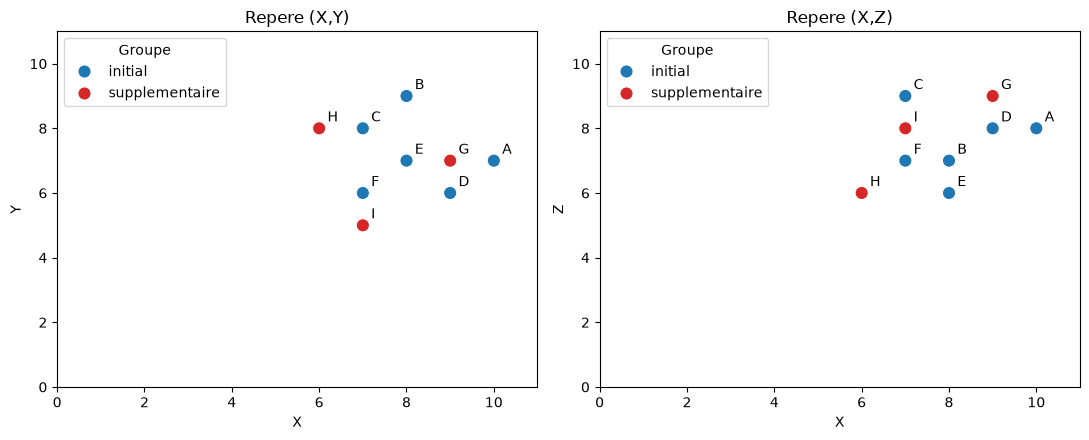

In [7]:
#palette de couleur pour separer les données de base et supp
palette = {"initial": "tab:blue", "supplementaire":"tab:red"}

#1 figure avec 2 panneaux (X,Y) et (Y,Z)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (a,b) in zip(axes, [("X","Y"), ("X", "Z")]):
    ax.set_ylim(0,11)
    ax.set_xlim(0,11)
    #mettre les points sur le graph et les colorer
    sns.scatterplot(data=df,x=a,y=b, hue="Groupe", palette=palette, s=90,ax=ax)
    #pour chaque marque on met la lettre corresp.
    for _, r in df.iterrows():
        ax.annotate(r["Marque"],(r[a],r[b]),textcoords="offset points", xytext=(6,5))
    #titre du panneau
    ax.set_title(f"Repere ({a},{b})")
plt.tight_layout()
plt.savefig("exo1_scatter.png", dpi=150) #sauvegarder l'image du plot
plt.show() #afficher le plot

In [ ]:
#Autres question (2->8)
df_clean=df[df["Groupe"]=="initial"].drop(columns="Groupe") #reinitialisation du dataset
df_clean

,Marque,X,Y,Z
0,A,10,7,8
1,B,8,9,7
2,C,7,8,9
3,D,9,6,8
4,E,8,7,6
5,F,7,6,7


In [ ]:
moy=df_clean.mean(numeric_only=True)
var=df_clean.var(ddof=1, numeric_only=True) #diviser par n-1 (echantillon)
ecart=df_clean.std(ddof=1,numeric_only=True) #diviser par n-1 (echantillon)
print(f"Moyenne: {moy}\nVariance: {var}\nEcart-Type: {ecart}")

Moyenne: X    8.166667
Y    7.166667
Z    7.500000
dtype: float64
Variance: X    1.366667
Y    1.366667
Z    1.100000
dtype: float64
Ecart-Type: X    1.169045
Y    1.169045
Z    1.048809
dtype: float64


In [ ]:
#Matrice Centré Reduite
r_c = df_clean.drop(columns="Marque") - moy #centrer
r_cr = r_c / ecart #réduire
r_cr

,X,Y,Z
0,1.568231,-0.142566,0.476731
1,-0.142566,1.568231,-0.476731
2,-0.997965,0.712832,1.430194
3,0.712832,-0.997965,0.476731
4,-0.142566,-0.142566,-1.430194
5,-0.997965,-0.997965,-0.476731


In [ ]:
# n = len(df_clean)
# R = r_cr.T @ r_cr / (n-1) # .T tranposé, @ multip matricielle

<Axes: >

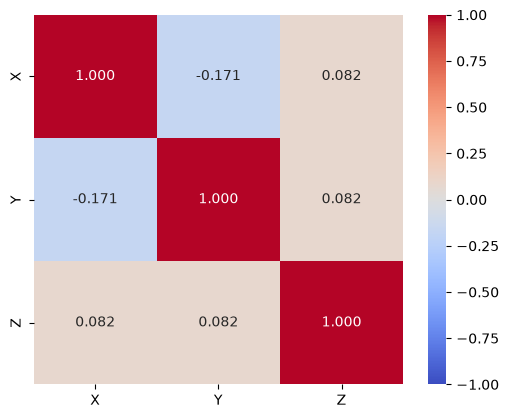

In [16]:
sns.heatmap(df_clean.corr(numeric_only=True), annot=True, fmt=".3f", cmap='coolwarm', vmin=-1, vmax=1, square=True)

In [ ]:
import numpy as np

In [ ]:
#orthogonality (si u1*u2 = 0 donc orthogonal)
u1 = np.array([2,-1,-1])
u2 = np.array([1,1,1])
print(u1 @ u2) #0

0
